In [1]:
%pip install -q pandas numpy matplotlib seaborn scikit-learn joblib

In [4]:
import pandas as pd

df = pd.read_csv(
    "/content/customer_churn_10_features_100_rows.csv"
)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (100, 11)


,CustomerID,Gender,SeniorCitizen,Partner,Dependents,Tenure,InternetService,TechSupport,Contract,MonthlyCharges,Churn
0,1,Male,0,No,Yes,29,DSL,Yes,Two Year,656,Yes
1,2,Male,0,Yes,Yes,30,No,Yes,Two Year,1114,Yes
2,3,Male,1,No,Yes,21,No,No,One Year,1438,No
3,4,Male,1,Yes,Yes,49,DSL,No,One Year,1383,No
4,5,Female,0,No,Yes,71,Fiber Optic,No,Two Year,1087,No


In [5]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nChurn distribution:")
print(df["Churn"].value_counts())

Dataset shape: (100, 11)

Column names:
['CustomerID', 'Gender', 'SeniorCitizen', 'Partner', 'Dependents', 'Tenure', 'InternetService', 'TechSupport', 'Contract', 'MonthlyCharges', 'Churn']

Missing values:
CustomerID         0
Gender             0
SeniorCitizen      0
Partner            0
Dependents         0
Tenure             0
InternetService    0
TechSupport        0
Contract           0
MonthlyCharges     0
Churn              0
dtype: int64

Duplicate rows: 0

Churn distribution:
Churn
No     63
Yes    37
Name: count, dtype: int64


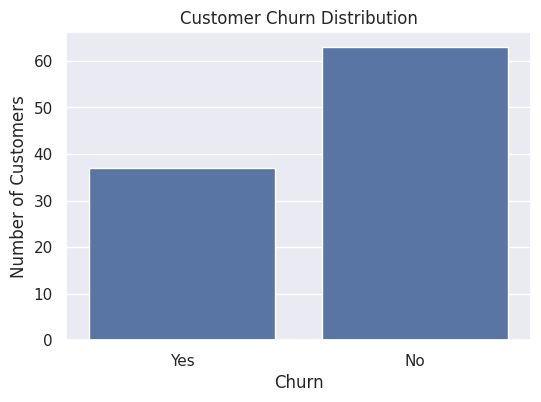

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme()

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Churn")
plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.show()

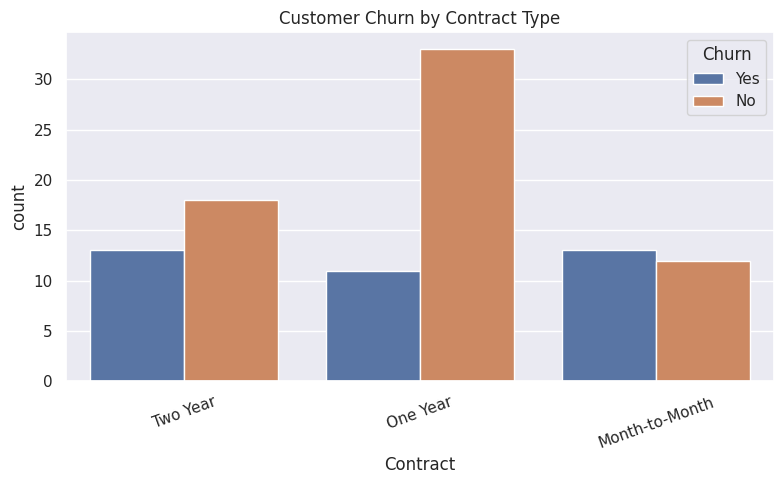

In [7]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Contract",
    hue="Churn"
)

plt.title("Customer Churn by Contract Type")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [8]:
%pip install -q pandas numpy matplotlib seaborn scikit-learn joblib

In [10]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [11]:
DATA_PATH = Path(
    "/content/customer_churn_10_features_100_rows.csv"
)

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Dataset shape: (100, 11)


,CustomerID,Gender,SeniorCitizen,Partner,Dependents,Tenure,InternetService,TechSupport,Contract,MonthlyCharges,Churn
0,1,Male,0,No,Yes,29,DSL,Yes,Two Year,656,Yes
1,2,Male,0,Yes,Yes,30,No,Yes,Two Year,1114,Yes
2,3,Male,1,No,Yes,21,No,No,One Year,1438,No
3,4,Male,1,Yes,Yes,49,DSL,No,One Year,1383,No
4,5,Female,0,No,Yes,71,Fiber Optic,No,Two Year,1087,No


In [12]:
# SECTION 3: Validate and clean the dataset

print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.to_frame("Data Type"))

print("\nMissing values:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nDuplicate rows:", df.duplicated().sum())

# Remove exact duplicate rows
df = df.drop_duplicates().copy()

# Check that the target column exists
if "Churn" not in df.columns:
    raise ValueError("The dataset must contain a 'Churn' column.")

# Standardize target labels
df["Churn"] = df["Churn"].astype("string").str.strip().str.title()

# Remove rows where the target is missing
df = df.dropna(subset=["Churn"]).copy()

# Validate target values
valid_values = {"Yes", "No"}
actual_values = set(df["Churn"].unique())

if not actual_values.issubset(valid_values):
    raise ValueError(f"Unexpected Churn values: {actual_values}")

print("\nChurn distribution:")
display(df["Churn"].value_counts().to_frame("Customer Count"))

print("\nData validation completed successfully!")

Dataset shape: (100, 11)

Column names:
['CustomerID', 'Gender', 'SeniorCitizen', 'Partner', 'Dependents', 'Tenure', 'InternetService', 'TechSupport', 'Contract', 'MonthlyCharges', 'Churn']

Data types:


,Data Type
CustomerID,int64
Gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
Tenure,int64
InternetService,object
TechSupport,object
Contract,object
MonthlyCharges,int64



Missing values:


,Missing Values
CustomerID,0
Gender,0
SeniorCitizen,0
Partner,0
Dependents,0
Tenure,0
InternetService,0
TechSupport,0
Contract,0
MonthlyCharges,0



Duplicate rows: 0

Churn distribution:


,Customer Count
Churn,
No,63
Yes,37



Data validation completed successfully!


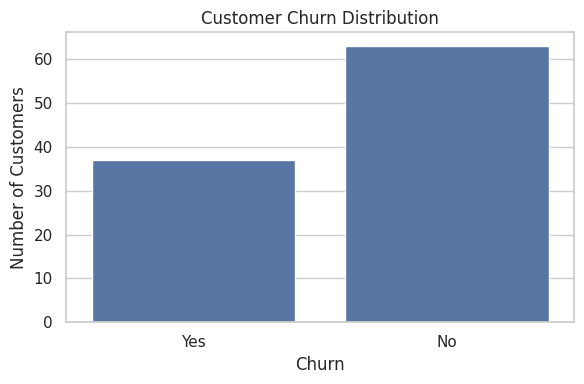

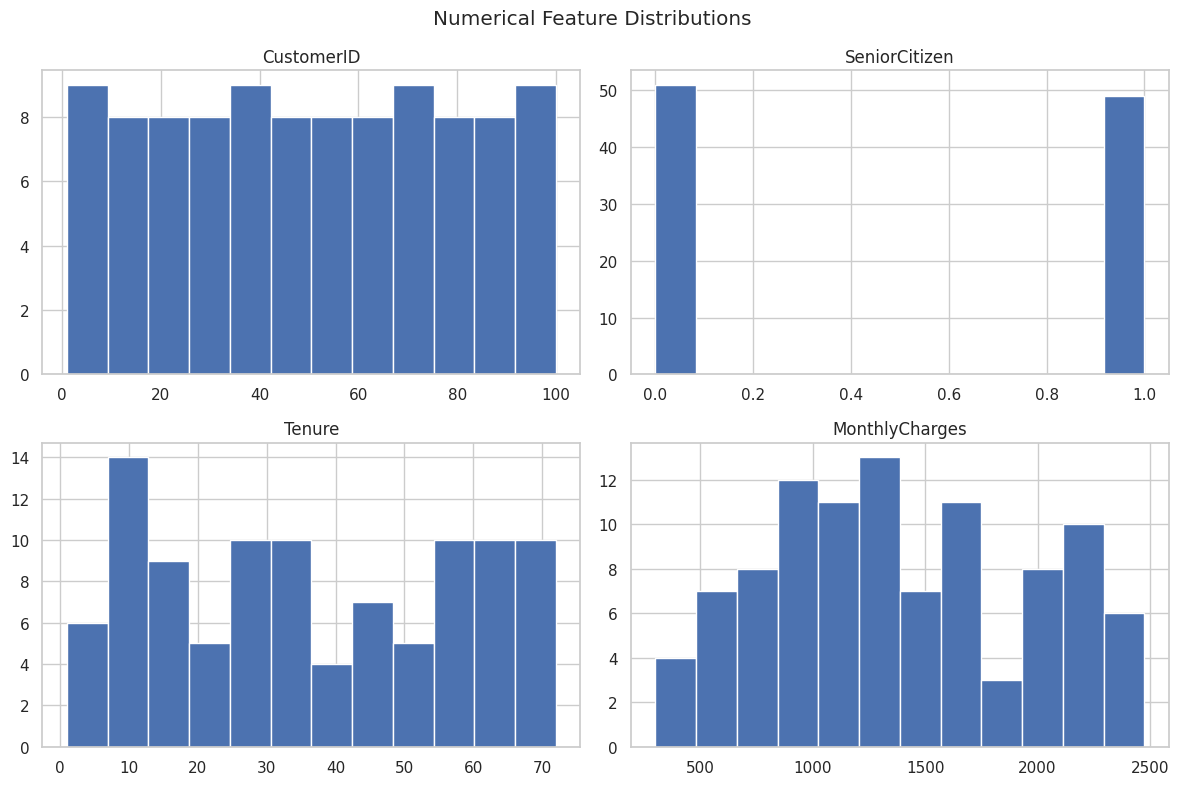

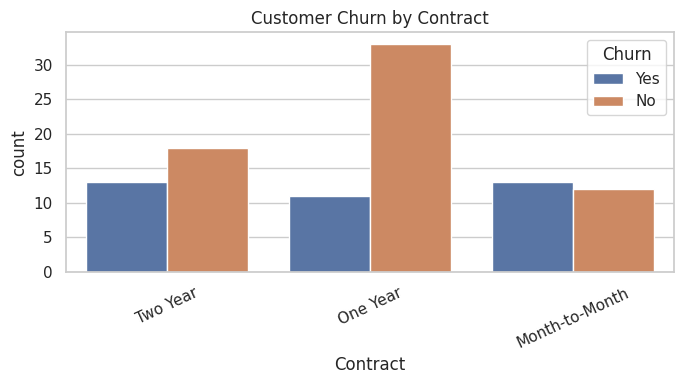

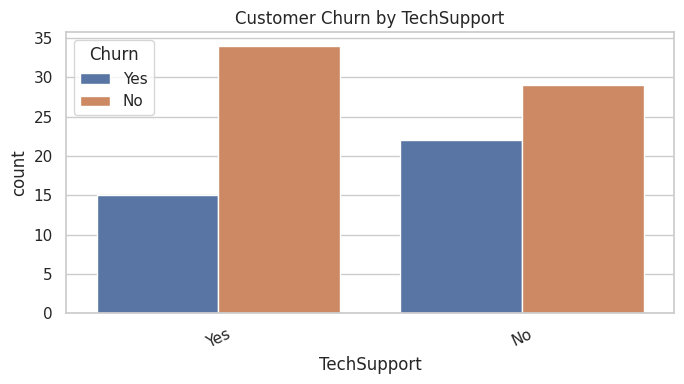

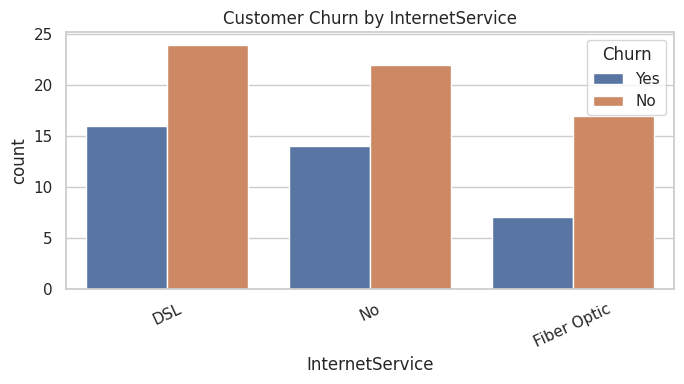

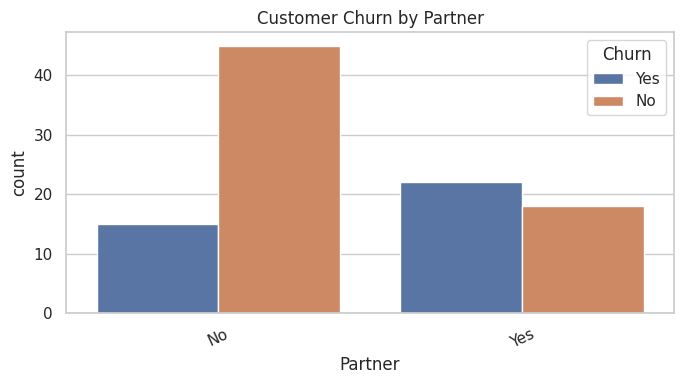

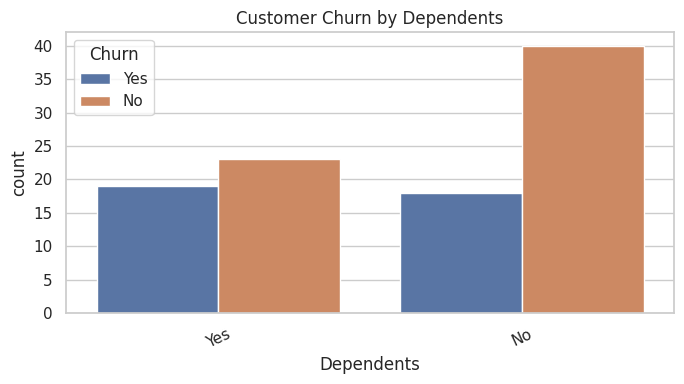

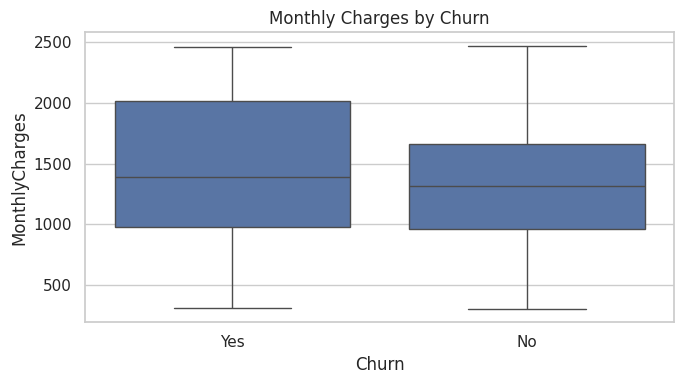

Observed churn percentage: 37.00%


In [13]:
# SECTION 4: Exploratory Data Analysis

sns.set_theme(style="whitegrid")

# 1. Overall churn distribution
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Churn")
plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

# 2. Numerical feature distributions
numeric_columns = df.select_dtypes(include=np.number).columns.tolist()

if numeric_columns:
    df[numeric_columns].hist(
        figsize=(12, 8),
        bins=12
    )
    plt.suptitle("Numerical Feature Distributions")
    plt.tight_layout()
    plt.show()

# 3. Churn by important categorical features
categorical_to_plot = [
    "Contract",
    "TechSupport",
    "InternetService",
    "Partner",
    "Dependents"
]

for feature in categorical_to_plot:
    if feature in df.columns:
        plt.figure(figsize=(7, 4))
        sns.countplot(data=df, x=feature, hue="Churn")
        plt.title(f"Customer Churn by {feature}")
        plt.xticks(rotation=25)
        plt.tight_layout()
        plt.show()

# 4. Monthly charges versus churn
if "MonthlyCharges" in df.columns:
    plt.figure(figsize=(7, 4))
    sns.boxplot(data=df, x="Churn", y="MonthlyCharges")
    plt.title("Monthly Charges by Churn")
    plt.tight_layout()
    plt.show()

# 5. Churn percentage
churn_percentage = (
    df["Churn"].eq("Yes").mean() * 100
)

print(f"Observed churn percentage: {churn_percentage:.2f}%")

In [14]:
# SECTION 5: Data preprocessing

# CustomerID is excluded because it is an identifier
X = df.drop(
    columns=["Churn", "CustomerID"],
    errors="ignore"
).copy()

# Convert target labels into numbers
y = df["Churn"].map({
    "No": 0,
    "Yes": 1
}).astype(int)

if y.nunique() < 2:
    raise ValueError(
        "The dataset must contain both Yes and No churn labels."
    )

# Identify numerical and categorical columns
numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

# Split data into training and testing sets
class_counts = y.value_counts()

stratify_y = (
    y if class_counts.min() >= 2 else None
)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=stratify_y
)

print("\nTraining records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining data prepared successfully!")

Numerical features: ['SeniorCitizen', 'Tenure', 'MonthlyCharges']
Categorical features: ['Gender', 'Partner', 'Dependents', 'InternetService', 'TechSupport', 'Contract']

Training records: 80
Testing records: 20

Training data prepared successfully!


In [15]:
# SECTION 6: Train machine-learning models

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=4,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        max_depth=5,
        class_weight="balanced",
        random_state=RANDOM_STATE
    )
}

fitted_models = {}
results = []

for model_name, estimator in models.items():

    print(f"Training {model_name}...")

    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", estimator)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)
    probabilities = pipeline.predict_proba(X_test)[:, 1]

    accuracy = accuracy_score(y_test, predictions)
    precision = precision_score(
        y_test, predictions, zero_division=0
    )
    recall = recall_score(
        y_test, predictions, zero_division=0
    )
    f1 = f1_score(
        y_test, predictions, zero_division=0
    )

    auc = (
        roc_auc_score(y_test, probabilities)
        if y_test.nunique() == 2
        else np.nan
    )

    results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1,
        "ROC-AUC": auc
    })

    fitted_models[model_name] = pipeline

# Compare model results
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1-score",
    ascending=False
).reset_index(drop=True)

print("\nModel comparison results:")
display(results_df.round(3))

# Select a demonstration model using test-set F1
best_model_name = results_df.iloc[0]["Model"]
best_model = fitted_models[best_model_name]

print("Selected demonstration model:", best_model_name)

Training Logistic Regression...
Training Decision Tree...
Training Random Forest...

Model comparison results:


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.7,0.545,0.857,0.667,0.714
1,Random Forest,0.7,0.600,0.429,0.500,0.714
2,Decision Tree,0.6,0.429,0.429,0.429,0.544


Selected demonstration model: Logistic Regression


Selected model: Logistic Regression

Classification report:
              precision    recall  f1-score   support

    No Churn       0.89      0.62      0.73        13
       Churn       0.55      0.86      0.67         7

    accuracy                           0.70        20
   macro avg       0.72      0.74      0.70        20
weighted avg       0.77      0.70      0.71        20



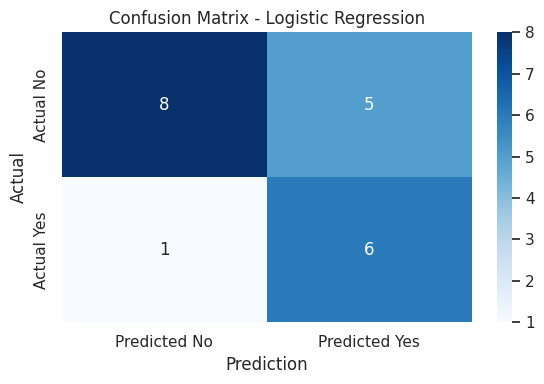

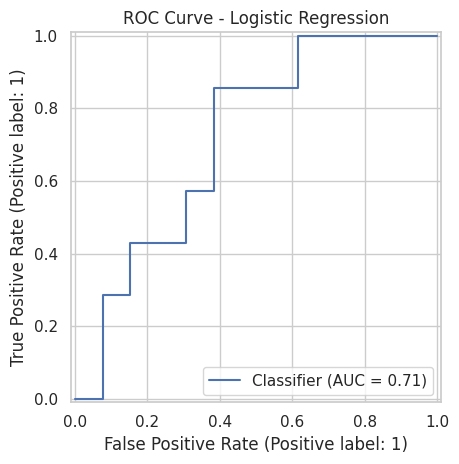

In [16]:
# SECTION 7: Model evaluation

y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1]

print("Selected model:", best_model_name)

print("\nClassification report:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=["No Churn", "Churn"],
        zero_division=0
    )
)

# Confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1]
)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Predicted No", "Predicted Yes"],
    yticklabels=["Actual No", "Actual Yes"]
)

plt.title(f"Confusion Matrix - {best_model_name}")
plt.xlabel("Prediction")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

# ROC curve
if y_test.nunique() == 2:
    RocCurveDisplay.from_predictions(y_test, y_prob)
    plt.title(f"ROC Curve - {best_model_name}")
    plt.tight_layout()
    plt.show()
else:
    print("ROC curve unavailable because the test set has one class.")

,Feature,Importance
14,cat__Contract_Month-to-Month,0.592916
6,cat__Partner_Yes,0.498830
5,cat__Partner_No,0.497844
15,cat__Contract_One Year,0.418937
0,num__SeniorCitizen,0.302270
12,cat__TechSupport_No,0.212072
13,cat__TechSupport_Yes,0.211086
1,num__Tenure,0.210999
9,cat__InternetService_DSL,0.208213
8,cat__Dependents_Yes,0.194432


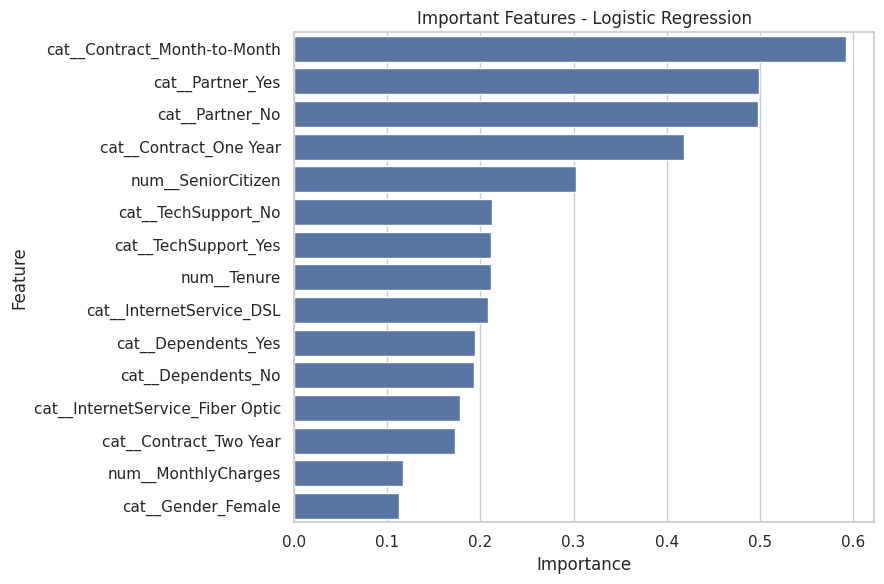

SHAP feature-importance plot:


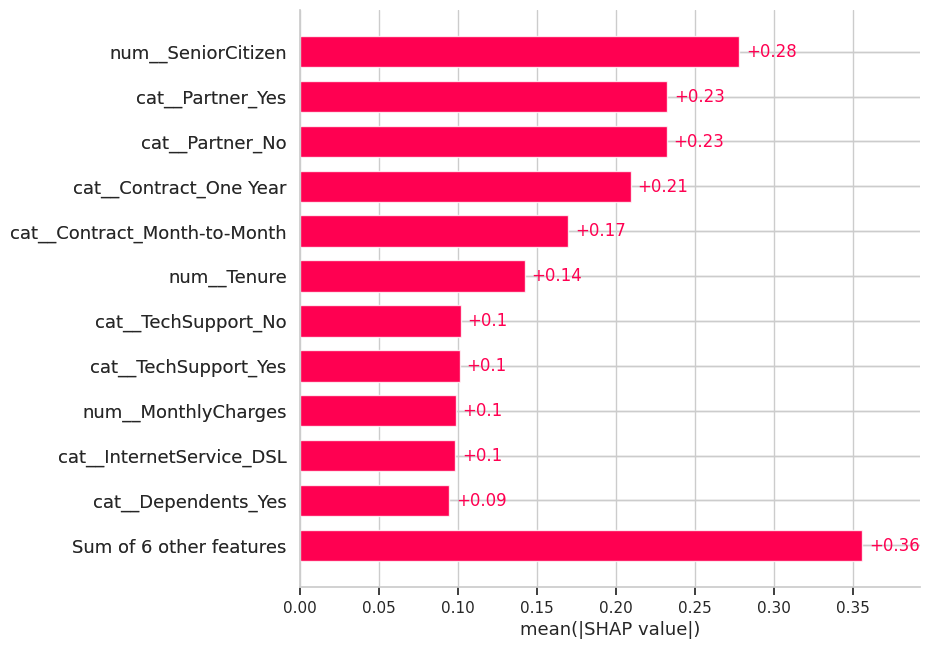

SHAP feature-impact plot:


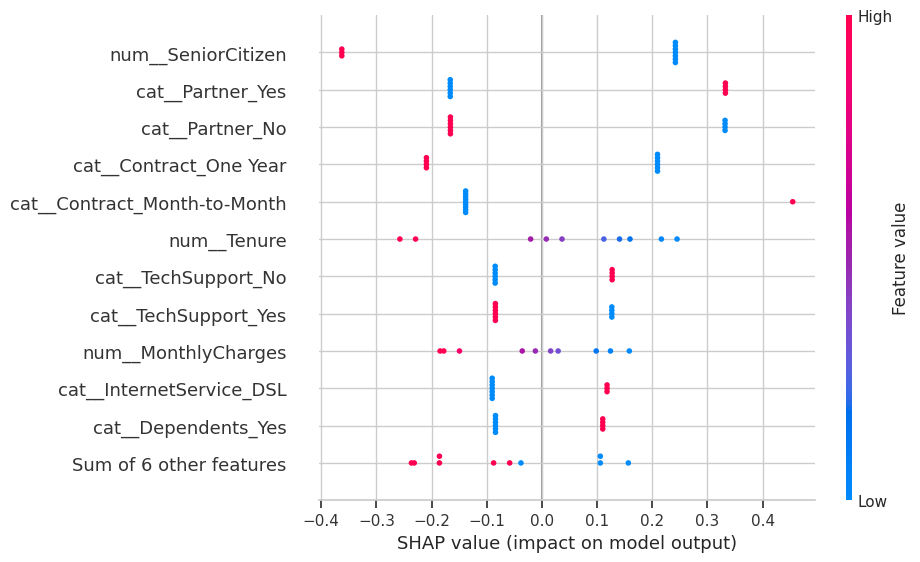

In [17]:
# SECTION 8: Model explainability

fitted_preprocessor = best_model.named_steps["preprocessor"]
estimator = best_model.named_steps["model"]

feature_names = fitted_preprocessor.get_feature_names_out()

importance = None

if hasattr(estimator, "feature_importances_"):
    importance = estimator.feature_importances_

elif hasattr(estimator, "coef_"):
    importance = np.abs(estimator.coef_[0])

if importance is not None:
    importance_df = pd.DataFrame({
        "Feature": feature_names,
        "Importance": importance
    })

    importance_df = importance_df.sort_values(
        by="Importance",
        ascending=False
    ).head(15)

    display(importance_df)

    plt.figure(figsize=(9, 6))
    sns.barplot(
        data=importance_df,
        x="Importance",
        y="Feature"
    )

    plt.title(f"Important Features - {best_model_name}")
    plt.tight_layout()
    plt.show()
else:
    print("Built-in feature importance is unavailable.")

# Optional SHAP explanation
try:
    import shap

    X_train_transformed = fitted_preprocessor.transform(X_train)
    X_test_transformed = fitted_preprocessor.transform(X_test)

    background = X_train_transformed[
        :min(30, X_train_transformed.shape[0])
    ]

    explain_data = X_test_transformed[
        :min(10, X_test_transformed.shape[0])
    ]

    explainer = shap.Explainer(
        estimator,
        background,
        feature_names=list(feature_names)
    )

    shap_values = explainer(explain_data)

    print("SHAP feature-importance plot:")
    shap.plots.bar(shap_values, max_display=12)

    print("SHAP feature-impact plot:")
    shap.plots.beeswarm(shap_values, max_display=12)

except ImportError:
    print("SHAP is not installed.")
    print("To install it, run %pip install shap in a separate cell.")

except Exception as error:
    print("SHAP could not run in this environment.")
    print("Reason:", str(error))
    print("Use the feature-importance plot above as a fallback.")

In [18]:
# SECTION 9: Predict churn for a new customer

# Start with typical values from the dataset
new_customer_values = {}

for column in X.columns:

    if pd.api.types.is_numeric_dtype(X[column]):
        new_customer_values[column] = X[column].median()

    else:
        modes = X[column].mode(dropna=True)

        if not modes.empty:
            new_customer_values[column] = modes.iloc[0]
        else:
            new_customer_values[column] = "Unknown"

# Customize example values if these columns exist
example_values = {
    "Gender": "Female",
    "SeniorCitizen": 0,
    "Partner": "No",
    "Dependents": "No",
    "Tenure": 4,
    "InternetService": "Fiber optic",
    "TechSupport": "No",
    "Contract": "Month-to-month"
}

for column, value in example_values.items():
    if column in X.columns:
        new_customer_values[column] = value

# Use the median monthly charge from the dataset
if "MonthlyCharges" in X.columns:
    new_customer_values["MonthlyCharges"] = X["MonthlyCharges"].median()

new_customer = pd.DataFrame(
    [new_customer_values],
    columns=X.columns
)

predicted_class = int(best_model.predict(new_customer)[0])

churn_probability = float(
    best_model.predict_proba(new_customer)[0, 1]
)

print("New customer details:")
display(new_customer)

print(
    "\nPrediction:",
    "Likely to Churn" if predicted_class == 1
    else "Likely to Stay"
)

print(
    f"Estimated churn probability: {churn_probability:.1%}"
)

New customer details:


,Gender,SeniorCitizen,Partner,Dependents,Tenure,InternetService,TechSupport,Contract,MonthlyCharges
0,Female,0,No,No,4,Fiber optic,No,Month-to-month,1318.5



Prediction: Likely to Churn
Estimated churn probability: 59.0%


In [19]:
# SECTION 10: Customer-retention recommendations

def retention_recommendations(customer):

    recommendations = []

    tenure = customer.get("Tenure", None)
    contract = str(customer.get("Contract", "")).lower()
    tech_support = str(
        customer.get("TechSupport", "")
    ).lower()
    monthly_charges = customer.get("MonthlyCharges", None)

    # Recommendation for new customers
    if pd.notna(tenure) and float(tenure) <= 6:
        recommendations.append(
            "Arrange an onboarding check-in and ask whether the service is working properly."
        )

    # Recommendation based on contract type
    if "month" in contract:
        recommendations.append(
            "Explain available contract options and their costs clearly."
        )

    # Recommendation based on support
    if tech_support == "no":
        recommendations.append(
            "Explain available technical support and offer help if needed."
        )

    # Recommendation based on monthly charges
    if (
        pd.notna(monthly_charges)
        and "MonthlyCharges" in df.columns
        and monthly_charges >= df["MonthlyCharges"].median()
    ):
        recommendations.append(
            "Review the customer's bill and explain suitable plan options."
        )

    if not recommendations:
        recommendations.append(
            "Conduct a routine satisfaction check-in and ask for feedback."
        )

    return recommendations


print("Customer-retention recommendations:\n")

for recommendation in retention_recommendations(
    new_customer.iloc[0].to_dict()
):
    print("-", recommendation)

Customer-retention recommendations:

- Arrange an onboarding check-in and ask whether the service is working properly.
- Explain available contract options and their costs clearly.
- Explain available technical support and offer help if needed.
- Review the customer's bill and explain suitable plan options.


In [20]:
# SECTION 11: Project Q&A assistant

def project_assistant(question):

    question = question.lower().strip()

    if any(word in question for word in [
        "dataset", "rows", "records", "customers"
    ]):
        return (
            f"The dataset contains {len(df)} rows "
            f"and {df.shape[1]} columns."
        )

    elif "churn rate" in question or "churn percentage" in question:
        rate = df["Churn"].eq("Yes").mean() * 100
        return f"The observed churn rate is {rate:.2f}%."

    elif "best model" in question or "selected model" in question:
        return (
            f"The selected demonstration model is "
            f"{best_model_name}, based on test-set F1-score."
        )

    elif any(word in question for word in [
        "accuracy", "precision", "recall", "f1"
    ]):
        row = results_df[
            results_df["Model"] == best_model_name
        ].iloc[0]

        return (
            f"Model: {best_model_name}\n"
            f"Accuracy: {row['Accuracy']:.3f}\n"
            f"Precision: {row['Precision']:.3f}\n"
            f"Recall: {row['Recall']:.3f}\n"
            f"F1-score: {row['F1-score']:.3f}\n"
            "These test-set results are uncertain because the dataset is small."
        )

    elif "recommend" in question or "retention" in question:
        return (
            "Possible actions include onboarding check-ins, "
            "explaining contract options, offering support, "
            "and reviewing billing."
        )

    else:
        return (
            "Try asking:\n"
            "- How many customers are in the dataset?\n"
            "- What is the churn rate?\n"
            "- Which model was selected?\n"
            "- What is the model accuracy?\n"
            "- What are the retention recommendations?"
        )


# Test the assistant
question = "What is the churn rate?"

print(project_assistant(question))

The observed churn rate is 37.00%.


In [21]:
# SECTION 12: Save model and evaluation results

import joblib

MODEL_PATH = "/content/customer_churn_best_pipeline.joblib"
RESULTS_PATH = "/content/customer_churn_model_comparison.csv"

joblib.dump(best_model, MODEL_PATH)
results_df.to_csv(RESULTS_PATH, index=False)

print("Model saved successfully:", MODEL_PATH)
print("Model comparison saved successfully:", RESULTS_PATH)

Model saved successfully: /content/customer_churn_best_pipeline.joblib
Model comparison saved successfully: /content/customer_churn_model_comparison.csv


In [22]:
# SECTION 13: Project summary

print("=" * 55)
print("CUSTOMER CHURN PREDICTION - PROJECT SUMMARY")
print("=" * 55)

print("Total customers:", len(df))
print("Total input features:", X.shape[1])
print("Selected demonstration model:", best_model_name)

print("\nModel comparison:")
display(results_df.round(3))

print("\nObserved churn rate:")
print(f"{df['Churn'].eq('Yes').mean() * 100:.2f}%")

print("\nProject completed successfully!")


CUSTOMER CHURN PREDICTION - PROJECT SUMMARY
Total customers: 100
Total input features: 9
Selected demonstration model: Logistic Regression

Model comparison:


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.7,0.545,0.857,0.667,0.714
1,Random Forest,0.7,0.600,0.429,0.500,0.714
2,Decision Tree,0.6,0.429,0.429,0.429,0.544



Observed churn rate:
37.00%

Project completed successfully!
